In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import json

DATA_DIR = Path("data")

files = [
    "Q5_configuration.json",
    "Q5_windows.csv",
    "Q5_weights.csv",
    "Q5_means.csv",
    "Q5_covariances.csv",
    "Q5_asset_returns.csv",
    "Q5_portfolio_returns.csv",
    "Q5_performance.csv",
    "Q1_historical_monthly_returns_through_2025.csv",
    "README_Q6.md"
]

for filename in files:
    path = DATA_DIR / filename
    print(f"{filename}: {'OK' if path.exists() else 'MISSING'}")

Q5_configuration.json: OK
Q5_windows.csv: OK
Q5_weights.csv: OK
Q5_means.csv: OK
Q5_covariances.csv: OK
Q5_asset_returns.csv: OK
Q5_portfolio_returns.csv: OK
Q5_performance.csv: OK
Q1_historical_monthly_returns_through_2025.csv: OK
README_Q6.md: OK


In [2]:
# Q6 - Step 2: Load and inspect Q5 handoff data

with open(DATA_DIR / "Q5_configuration.json", "r", encoding="utf-8") as f:
    config = json.load(f)

windows = pd.read_csv(DATA_DIR / "Q5_windows.csv")
weights = pd.read_csv(DATA_DIR / "Q5_weights.csv")
means = pd.read_csv(DATA_DIR / "Q5_means.csv")
covariances = pd.read_csv(DATA_DIR / "Q5_covariances.csv")
asset_returns = pd.read_csv(DATA_DIR / "Q5_asset_returns.csv")
portfolio_returns = pd.read_csv(DATA_DIR / "Q5_portfolio_returns.csv")
performance = pd.read_csv(DATA_DIR / "Q5_performance.csv")
historical_returns = pd.read_csv(
    DATA_DIR / "Q1_historical_monthly_returns_through_2025.csv"
)

print("=== Q5 Configuration ===")
print(json.dumps(config, indent=2, ensure_ascii=False))

print("\n=== Data Shapes and Columns ===")

datasets = {
    "Windows": windows,
    "Weights": weights,
    "Means": means,
    "Covariances": covariances,
    "Asset Returns": asset_returns,
    "Portfolio Returns": portfolio_returns,
    "Performance": performance,
    "Historical Returns": historical_returns
}

for name, df in datasets.items():
    print(f"\n{name}: {df.shape}")
    print("Columns:", df.columns.tolist())
    print(df.head(2).to_string(index=False))

=== Q5 Configuration ===
{
  "asset_order": [
    "ASA52 Index",
    "NDDLWI Index",
    "NDLEEGF Index",
    "RDAU Index",
    "FDCIISAH Index",
    "HEDGNAV Index",
    "BACM0 Index",
    "H03432AU Index",
    "BAUBIL Index"
  ],
  "growth_fractions": [
    1.0,
    1.0,
    1.0,
    1.0,
    1.0,
    0.5,
    0.0,
    0.0,
    0.0
  ],
  "targets": {
    "Defensive": 0.3,
    "Balanced": 0.7,
    "Aggressive": 0.9
  },
  "estimation_months": 60,
  "oos_months": 12,
  "t0_years": [
    2015,
    2016,
    2017,
    2018,
    2019,
    2020,
    2021,
    2022,
    2023,
    2024
  ],
  "annualisation": {
    "mean_multiplier": 12,
    "covariance_multiplier": 12,
    "ddof": 1
  },
  "constraints": {
    "sum_weights": 1,
    "lower": 0,
    "upper": 0.5
  },
  "oos_strategy": "fixed-weight monthly rebalancing; annual target update; no transaction costs",
  "units": {
    "returns_means_volatility_weights": "decimal",
    "covariance": "annualised decimal return squared"
  },
  "solv

In [3]:
# Q6 - Step 3: Baseline configuration

Q6_CONFIG = {
    "saa_name": "Balanced",
    "growth_target": 0.70,
    "estimation_months": 60,
    "rebalancing_frequency": "Monthly",
    "gamma": 5.0,
    "tactical_deviation": 0.10,
    "min_weight": 0.0,
    "max_weight": 0.50,
    "transaction_cost": 0.0
}

ASSETS = config["asset_order"]
GROWTH_FRACTIONS = np.array(config["growth_fractions"])

# Extract the matching Q5 Balanced SAA weights
balanced_weights = (
    weights.loc[weights["Portfolio"] == "Balanced"]
    .sort_values("T0")
    .reset_index(drop=True)
)

# Check that every historical window has a matching SAA
assert len(balanced_weights) == len(windows)
assert balanced_weights["T0"].tolist() == windows["T0"].tolist()

# Check strategic portfolio constraints
saa_matrix = balanced_weights[ASSETS].to_numpy(dtype=float)

assert np.allclose(saa_matrix.sum(axis=1), 1.0, atol=1e-7)
assert np.all(saa_matrix >= -1e-7)
assert np.all(saa_matrix <= 0.5 + 1e-7)

growth_exposure = saa_matrix @ GROWTH_FRACTIONS
assert np.allclose(growth_exposure, 0.70, atol=1e-6)

# Tactical bounds around each year's Balanced SAA
lower_bounds = np.maximum(
    Q6_CONFIG["min_weight"],
    saa_matrix - Q6_CONFIG["tactical_deviation"]
)

upper_bounds = np.minimum(
    Q6_CONFIG["max_weight"],
    saa_matrix + Q6_CONFIG["tactical_deviation"]
)

# Check feasibility of the tactical bounds
assert np.all(lower_bounds.sum(axis=1) <= 1.0 + 1e-8)
assert np.all(upper_bounds.sum(axis=1) >= 1.0 - 1e-8)

print("=== Q6 Baseline Configuration ===")
print(json.dumps(Q6_CONFIG, indent=2))

print("\nNumber of assets:", len(ASSETS))
print("Number of SAA windows:", len(balanced_weights))

print("\n=== First SAA Window: 2015 ===")
bounds_check = pd.DataFrame({
    "Asset": ASSETS,
    "SAA_weight": saa_matrix[0],
    "Tactical_lower": lower_bounds[0],
    "Tactical_upper": upper_bounds[0]
})

print(bounds_check.to_string(index=False))

print("\nAll configuration checks passed.")

=== Q6 Baseline Configuration ===
{
  "saa_name": "Balanced",
  "growth_target": 0.7,
  "estimation_months": 60,
  "rebalancing_frequency": "Monthly",
  "gamma": 5.0,
  "tactical_deviation": 0.1,
  "min_weight": 0.0,
  "max_weight": 0.5,
  "transaction_cost": 0.0
}

Number of assets: 9
Number of SAA windows: 10

=== First SAA Window: 2015 ===
         Asset   SAA_weight  Tactical_lower  Tactical_upper
   ASA52 Index 2.026811e-17        0.000000        0.100000
  NDDLWI Index 0.000000e+00        0.000000        0.100000
 NDLEEGF Index 4.987776e-02        0.000000        0.149878
    RDAU Index 8.038016e-02        0.000000        0.180380
FDCIISAH Index 3.197421e-01        0.219742        0.419742
 HEDGNAV Index 5.000000e-01        0.400000        0.500000
   BACM0 Index 0.000000e+00        0.000000        0.100000
H03432AU Index 3.586325e-17        0.000000        0.100000
  BAUBIL Index 5.000000e-02        0.000000        0.150000

All configuration checks passed.


In [4]:
# ============================================================
# Q6(b) - Step 4: Monthly Rolling Estimation
# ============================================================

# 1. Prepare historical monthly returns
hist = historical_returns.copy()
hist["Date"] = pd.to_datetime(hist["Date"])
hist = hist.sort_values("Date").reset_index(drop=True)

# 2. Prepare Q5 out-of-sample dates
oos = asset_returns.copy()
oos["Date"] = pd.to_datetime(oos["Date"])
oos = oos.sort_values("Date").reset_index(drop=True)

# 3. Check data consistency
assert hist["Date"].is_unique
assert oos["Date"].is_unique
assert hist[ASSETS].notna().all().all()
assert oos[ASSETS].notna().all().all()

assert len(oos) == 120

# 4. Construct monthly rolling estimates
rolling_estimates = []

for _, row in oos.iterrows():

    current_date = row["Date"]

    # Only use observations strictly before current OOS month
    past_data = hist.loc[
        hist["Date"] < current_date
    ].tail(Q6_CONFIG["estimation_months"])

    assert len(past_data) == 60

    # Annualised expected returns
    m_k = (
        past_data[ASSETS].mean().to_numpy()
        * 12
    )

    # Annualised sample covariance matrix
    C_k = (
        past_data[ASSETS].cov(ddof=1).to_numpy()
        * 12
    )

    rolling_estimates.append({
        "T0": row["T0"],
        "Date": current_date,
        "Estimation_start": past_data["Date"].iloc[0],
        "Estimation_end": past_data["Date"].iloc[-1],
        "m_k": m_k,
        "C_k": C_k
    })

# 5. Check rolling estimation results
assert len(rolling_estimates) == 120

for item in rolling_estimates:
    assert item["Estimation_end"] < item["Date"]
    assert item["m_k"].shape == (9,)
    assert item["C_k"].shape == (9, 9)
    assert np.all(np.isfinite(item["m_k"]))
    assert np.all(np.isfinite(item["C_k"]))

# 6. Display first and last estimation windows
print("=== Q6(b): Monthly Rolling Estimation ===")
print("Number of monthly estimates:", len(rolling_estimates))

for label, item in [
    ("First", rolling_estimates[0]),
    ("Last", rolling_estimates[-1])
]:
    print(f"\n=== {label} Estimation ===")
    print("OOS Date:", item["Date"].date())
    print("Estimation Start:", item["Estimation_start"].date())
    print("Estimation End:", item["Estimation_end"].date())
    print("Mean Vector Shape:", item["m_k"].shape)
    print("Covariance Matrix Shape:", item["C_k"].shape)

print("\nAll rolling estimation checks passed.")

=== Q6(b): Monthly Rolling Estimation ===
Number of monthly estimates: 120

=== First Estimation ===
OOS Date: 2016-01-29
Estimation Start: 2011-01-31
Estimation End: 2015-12-31
Mean Vector Shape: (9,)
Covariance Matrix Shape: (9, 9)

=== Last Estimation ===
OOS Date: 2025-12-31
Estimation Start: 2020-12-31
Estimation End: 2025-11-28
Mean Vector Shape: (9,)
Covariance Matrix Shape: (9, 9)

All rolling estimation checks passed.


In [5]:
# ============================================================
# Q6(b) - Step 5: Monthly Tactical Optimisation
# ============================================================

from scipy.optimize import minimize

taa_results = []

for item in rolling_estimates:

    current_date = item["Date"]
    t0 = item["T0"]

    # 1. Match the corresponding annual SAA weights
    saa_row = balanced_weights.loc[
        balanced_weights["T0"] == t0
    ]

    assert len(saa_row) == 1

    saa_w = saa_row[ASSETS].iloc[0].to_numpy(dtype=float)

    # 2. Tactical bounds around the SAA weights
    lb = np.maximum(
        Q6_CONFIG["min_weight"],
        saa_w - Q6_CONFIG["tactical_deviation"]
    )

    ub = np.minimum(
        Q6_CONFIG["max_weight"],
        saa_w + Q6_CONFIG["tactical_deviation"]
    )

    # 3. Estimated mean and covariance
    m_k = item["m_k"]
    C_k = item["C_k"]
    gamma = Q6_CONFIG["gamma"]

    # 4. Negative mean-variance utility (for minimisation)
    def objective(x):
        return -(
            x @ m_k
            - (gamma / 2) * (x @ C_k @ x)
        )

    # 5. Fully invested constraint
    constraints = [
        {
            "type": "eq",
            "fun": lambda x: np.sum(x) - 1.0
        }
    ]

    # 6. Solve the optimisation problem
    result = minimize(
        objective,
        x0=saa_w,
        method="SLSQP",
        bounds=list(zip(lb, ub)),
        constraints=constraints,
        options={
            "ftol": 1e-10,
            "maxiter": 2000
        }
    )

    if not result.success:
        raise RuntimeError(
            f"Optimisation failed on {current_date}: "
            f"{result.message}"
        )

    x_opt = result.x

    # 7. Verify optimised weights
    assert np.isclose(x_opt.sum(), 1.0, atol=1e-6)
    assert np.all(x_opt >= lb - 1e-6)
    assert np.all(x_opt <= ub + 1e-6)

    # 8. Save monthly results
    record = {
        "Date": current_date,
        "T0": t0,
        "Expected_Return": x_opt @ m_k,
        "Expected_Volatility": np.sqrt(x_opt @ C_k @ x_opt),
        "Growth_Exposure": x_opt @ GROWTH_FRACTIONS,
        "Optimisation_Success": result.success
    }

    record.update(dict(zip(ASSETS, x_opt)))

    taa_results.append(record)

# 9. Convert results to DataFrame
taa_weights = pd.DataFrame(taa_results)

# 10. Display results
print("=== Q6(b): Monthly Tactical Optimisation ===")
print("Number of optimisations:", len(taa_weights))
print("Successful optimisations:",
      taa_weights["Optimisation_Success"].sum())

print("\n=== First 5 Months ===")
print(
    taa_weights[
        ["Date", "T0", "Expected_Return",
         "Expected_Volatility", "Growth_Exposure"]
    ].head().to_string(index=False)
)

print("\n=== First Month: Optimal Weights ===")
print(
    taa_weights[["Date"] + ASSETS]
    .head(1)
    .to_string(index=False)
)

print("\nAll tactical optimisation checks passed.")

=== Q6(b): Monthly Tactical Optimisation ===
Number of optimisations: 120
Successful optimisations: 120

=== First 5 Months ===
      Date         T0  Expected_Return  Expected_Volatility  Growth_Exposure
2016-01-29 2015-12-31         0.095361             0.061382              0.8
2016-02-29 2015-12-31         0.092230             0.061423              0.8
2016-03-31 2015-12-31         0.088133             0.060990              0.8
2016-04-29 2015-12-31         0.096200             0.060959              0.8
2016-05-31 2015-12-31         0.094348             0.060847              0.8

=== First Month: Optimal Weights ===
      Date  ASA52 Index  NDDLWI Index  NDLEEGF Index  RDAU Index  FDCIISAH Index  HEDGNAV Index  BACM0 Index  H03432AU Index  BAUBIL Index
2016-01-29          0.0           0.0   8.294506e-18     0.18038         0.41962            0.4 4.344066e-17    4.762307e-17  6.128714e-17

All tactical optimisation checks passed.


In [6]:
# ============================================================
# Q6(b) - Step 6: Out-of-Sample Backtest
# ============================================================

# 1. Prepare TAA monthly weights
taa_w = taa_weights.copy()
taa_w["Date"] = pd.to_datetime(taa_w["Date"])

# 2. Prepare actual out-of-sample asset returns
actual = asset_returns.copy()
actual["Date"] = pd.to_datetime(actual["Date"])

# 3. Match TAA weights with actual asset returns
backtest = taa_w.merge(
    actual[["Date"] + ASSETS],
    on="Date",
    how="inner",
    suffixes=("_weight", "_return"),
    validate="one_to_one"
)

assert len(backtest) == 120

# 4. Calculate realised TAA monthly returns
weight_cols = [f"{asset}_weight" for asset in ASSETS]
return_cols = [f"{asset}_return" for asset in ASSETS]

W = backtest[weight_cols].to_numpy(dtype=float)
R = backtest[return_cols].to_numpy(dtype=float)

backtest["TAA_Return"] = np.sum(W * R, axis=1)

# 5. Calculate cumulative TAA wealth
backtest = backtest.sort_values("Date").reset_index(drop=True)

backtest["TAA_Wealth"] = (
    1.0 + backtest["TAA_Return"]
).cumprod()

# 6. Inspect Q5 benchmark columns before merging
print("=== Q5 Portfolio Returns Columns ===")
print(portfolio_returns.columns.tolist())

print("\n=== Q6(b): TAA Backtest ===")
print("Number of OOS months:", len(backtest))

print("\n=== First 5 Months ===")
print(
    backtest[
        ["Date", "TAA_Return", "TAA_Wealth"]
    ].head().to_string(index=False)
)

print("\n=== Final TAA Wealth ===")
print(backtest["TAA_Wealth"].iloc[-1])

print("\nTAA out-of-sample return calculation completed.")

=== Q5 Portfolio Returns Columns ===
['T0', 'Portfolio', 'Date', 'Monthly_return', 'Block_wealth', 'Linked_wealth']

=== Q6(b): TAA Backtest ===
Number of OOS months: 120

=== First 5 Months ===
      Date  TAA_Return  TAA_Wealth
2016-01-29   -0.000816    0.999184
2016-02-29    0.003639    1.002821
2016-03-31    0.027617    1.030516
2016-04-29    0.006927    1.037654
2016-05-31    0.010582    1.048635

=== Final TAA Wealth ===
1.869971330429731

TAA out-of-sample return calculation completed.


In [7]:
# ============================================================
# Q6(b) - Step 7: TAA vs Balanced SAA
# ============================================================

# 1. Extract Q5 Balanced SAA monthly returns
saa_benchmark = portfolio_returns.loc[
    portfolio_returns["Portfolio"] == "Balanced",
    ["Date", "Monthly_return"]
].copy()

saa_benchmark["Date"] = pd.to_datetime(
    saa_benchmark["Date"]
)

saa_benchmark = saa_benchmark.rename(
    columns={"Monthly_return": "SAA_Return"}
)

# 2. Match SAA and TAA by date
comparison = backtest[
    ["Date", "TAA_Return", "TAA_Wealth"]
].merge(
    saa_benchmark,
    on="Date",
    how="inner",
    validate="one_to_one"
)

comparison = comparison.sort_values(
    "Date"
).reset_index(drop=True)

assert len(comparison) == 120

# 3. Calculate SAA cumulative wealth
comparison["SAA_Wealth"] = (
    1.0 + comparison["SAA_Return"]
).cumprod()

# 4. Calculate performance metrics
def calculate_performance(monthly_returns):

    r = np.asarray(monthly_returns, dtype=float)

    annual_return = 12 * np.mean(r)
    annual_volatility = np.std(r, ddof=1) * np.sqrt(12)
    cumulative_return = np.prod(1 + r) - 1

    return {
        "Annualised_Return": annual_return,
        "Annualised_Volatility": annual_volatility,
        "Cumulative_Return": cumulative_return,
        "Final_Wealth": np.prod(1 + r)
    }

taa_metrics = calculate_performance(
    comparison["TAA_Return"]
)

saa_metrics = calculate_performance(
    comparison["SAA_Return"]
)

performance_comparison = pd.DataFrame(
    [taa_metrics, saa_metrics],
    index=["TAA", "Balanced SAA"]
)

# Mean Annual OOS Volatility (10 annual blocks)
def mean_annual_oos_volatility(returns, dates):
    df = pd.DataFrame({
        "Date": pd.to_datetime(dates),
        "Return": np.asarray(returns, dtype=float)
    })

    annual_vol = df.groupby(
        df["Date"].dt.year
    )["Return"].apply(
        lambda r: r.std(ddof=1) * np.sqrt(12)
    )

    assert len(annual_vol) == 10
    assert (df.groupby(df["Date"].dt.year).size() == 12).all()

    return annual_vol.mean()


performance_comparison["Mean_Annual_OOS_Volatility"] = [
    mean_annual_oos_volatility(
        comparison["TAA_Return"],
        comparison["Date"]
    ),
    mean_annual_oos_volatility(
        comparison["SAA_Return"],
        comparison["Date"]
    )
]

# Place the new metric after full-period volatility
performance_comparison = performance_comparison[
    [
        "Annualised_Return",
        "Annualised_Volatility",
        "Mean_Annual_OOS_Volatility",
        "Cumulative_Return",
        "Final_Wealth"
    ]
]

# 5. Display results
print("=== Q6(b): TAA vs Balanced SAA ===")

print("\n=== Performance Comparison ===")
print(performance_comparison.round(6))

print("\n=== First 5 Months ===")
print(
    comparison[
        ["Date", "TAA_Return", "SAA_Return",
         "TAA_Wealth", "SAA_Wealth"]
    ].head().to_string(index=False)
)

print("\nComparison completed.")

=== Q6(b): TAA vs Balanced SAA ===

=== Performance Comparison ===
              Annualised_Return  Annualised_Volatility  \
TAA                    0.066334               0.083327   
Balanced SAA           0.069947               0.074026   

              Mean_Annual_OOS_Volatility  Cumulative_Return  Final_Wealth  
TAA                             0.072732           0.869971      1.869971  
Balanced SAA                    0.064770           0.953891      1.953891  

=== First 5 Months ===
      Date  TAA_Return  SAA_Return  TAA_Wealth  SAA_Wealth
2016-01-29   -0.000816   -0.006631    0.999184    0.993369
2016-02-29    0.003639   -0.000946    1.002821    0.992429
2016-03-31    0.027617    0.024503    1.030516    1.016746
2016-04-29    0.006927    0.004445    1.037654    1.021266
2016-05-31    0.010582    0.006974    1.048635    1.028388

Comparison completed.


In [8]:
# ============================================================
# Q6 - Step 8: Inspect Q5 Performance Definitions
# ============================================================

print("=== Q5 Performance Columns ===")
print(performance.columns.tolist())

print("\n=== Q5 Balanced Performance ===")
print(
    performance.loc[
        performance["Portfolio"] == "Balanced"
    ].to_string(index=False)
)

=== Q5 Performance Columns ===
['T0', 'Estimation_start', 'Estimation_end', 'Estimation_count', 'OOS_start', 'OOS_end', 'OOS_count', 'Portfolio', 'Growth_target', 'Predicted_annual_return', 'Realised_annualised_return', 'Return_error_realised_minus_predicted', 'Predicted_annual_volatility', 'Realised_annualised_volatility', 'Volatility_error_realised_minus_predicted', 'OOS_compounded_return', 'OOS_terminal_wealth', 'Return_rank_highest_first', 'Volatility_rank_lowest_first', 'Compounded_return_rank_highest_first']

=== Q5 Balanced Performance ===
        T0 Estimation_start Estimation_end  Estimation_count  OOS_start    OOS_end  OOS_count Portfolio  Growth_target  Predicted_annual_return  Realised_annualised_return  Return_error_realised_minus_predicted  Predicted_annual_volatility  Realised_annualised_volatility  Volatility_error_realised_minus_predicted  OOS_compounded_return  OOS_terminal_wealth  Return_rank_highest_first  Volatility_rank_lowest_first  Compounded_return_rank_highest

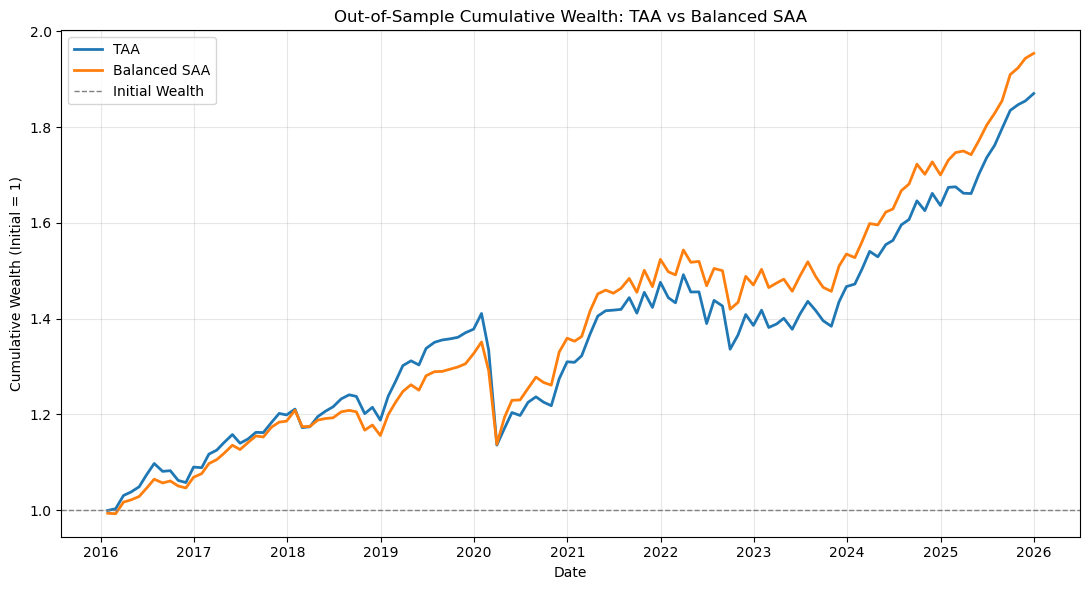

=== Final Wealth Comparison ===
      Date  TAA_Wealth  SAA_Wealth
2025-12-31    1.869971    1.953891


In [9]:
# ============================================================
# Q6 - Step 9: Cumulative Wealth Comparison
# ============================================================

import matplotlib.pyplot as plt

plt.figure(figsize=(11, 6))

plt.plot(
    comparison["Date"],
    comparison["TAA_Wealth"],
    label="TAA",
    linewidth=2
)

plt.plot(
    comparison["Date"],
    comparison["SAA_Wealth"],
    label="Balanced SAA",
    linewidth=2
)

plt.axhline(
    y=1.0,
    linestyle="--",
    linewidth=1,
    color="gray",
    label="Initial Wealth"
)

plt.title("Out-of-Sample Cumulative Wealth: TAA vs Balanced SAA")
plt.xlabel("Date")
plt.ylabel("Cumulative Wealth (Initial = 1)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("=== Final Wealth Comparison ===")
print(
    comparison[
        ["Date", "TAA_Wealth", "SAA_Wealth"]
    ].tail(1).to_string(index=False)
)

In [10]:
# Q6 - Step 10: Verify Q5 performance calculation

first_t0 = balanced_weights["T0"].iloc[0]

r = portfolio_returns.loc[
    (portfolio_returns["Portfolio"] == "Balanced") &
    (portfolio_returns["T0"] == first_t0),
    "Monthly_return"
].to_numpy(dtype=float)

q5_record = performance.loc[
    (performance["Portfolio"] == "Balanced") &
    (performance["T0"] == first_t0)
].iloc[0]

# Recalculate using Q5 monthly returns
calculated_annual_return = 12 * np.mean(r)
calculated_compounded_return = np.prod(1 + r) - 1

# Compare with Q5 reported results
print("=== Annualised Return ===")
print("Q5 reported:", q5_record["Realised_annualised_return"])
print("Recalculated:", calculated_annual_return)
print("Match:", np.isclose(
    q5_record["Realised_annualised_return"],
    calculated_annual_return
))

print("\n=== Compounded Return ===")
print("Q5 reported:", q5_record["OOS_compounded_return"])
print("Recalculated:", calculated_compounded_return)
print("Match:", np.isclose(
    q5_record["OOS_compounded_return"],
    calculated_compounded_return
))

=== Annualised Return ===
Q5 reported: 0.0672596108564647
Recalculated: 0.0672596108564647
Match: True

=== Compounded Return ===
Q5 reported: 0.068537811178901
Recalculated: 0.06853781117890101
Match: True


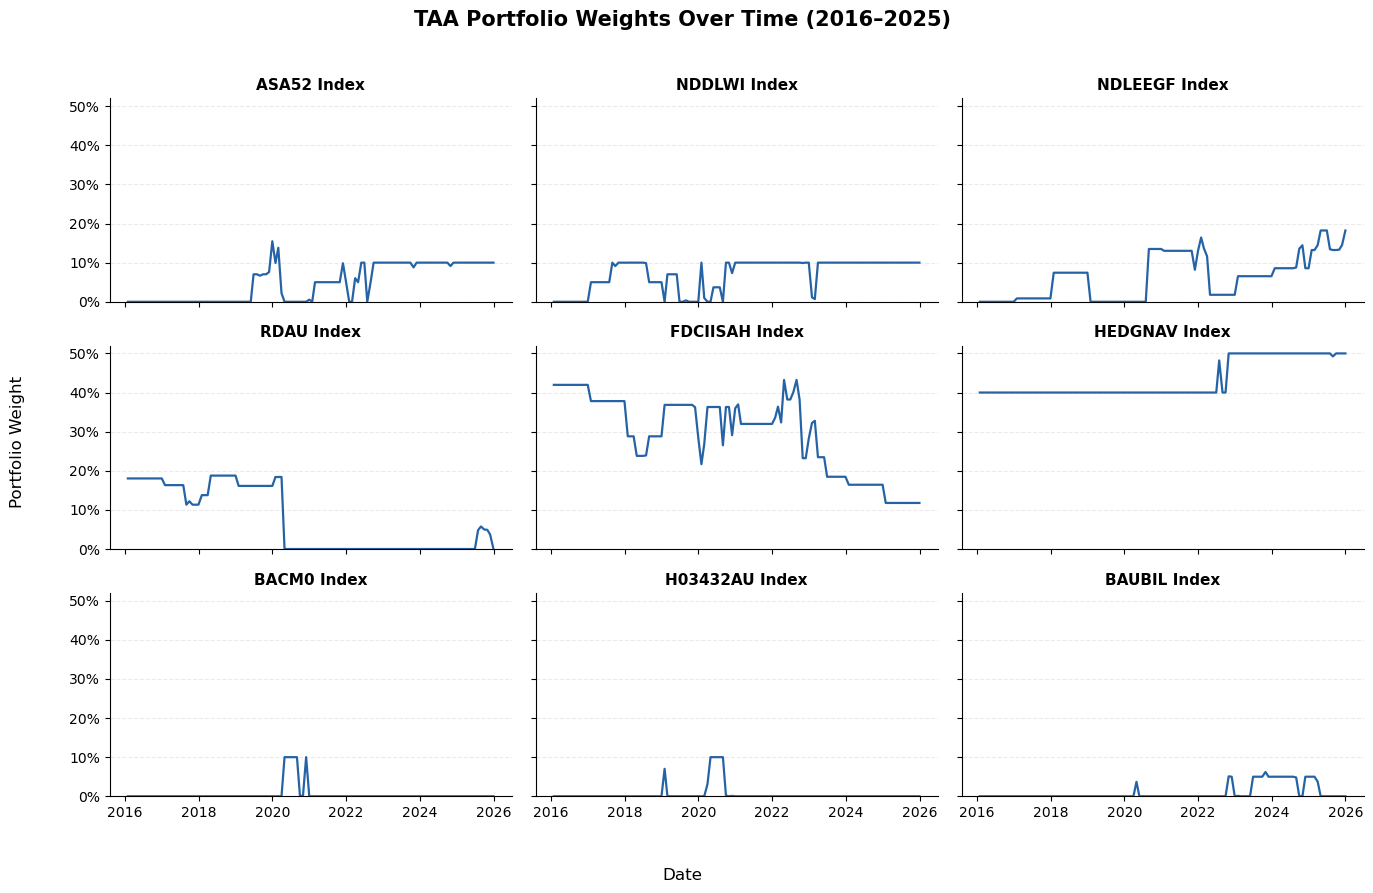

=== TAA Weight Variation Summary ===


,Mean_Weight,Min_Weight,Max_Weight,Std_Weight
FDCIISAH Index,0.2934,0.1178,0.4322,0.0989
RDAU Index,0.0726,0.0000,0.1877,0.0825
NDLEEGF Index,0.0625,0.0000,0.1822,0.0572
ASA52 Index,0.0482,0.0000,0.1547,0.0471
HEDGNAV Index,0.4331,0.4000,0.5000,0.0471
NDDLWI Index,0.0707,0.0000,0.1000,0.0407
BACM0 Index,0.0050,0.0000,0.1000,0.0219
H03432AU Index,0.0050,0.0000,0.1000,0.0211
BAUBIL Index,0.0095,0.0000,0.0621,0.0196



Weight history checks passed.


In [11]:
# ============================================================
# Q6(d) - Step 11: Tactical Portfolio Weights Over Time
# ============================================================

import matplotlib.pyplot as plt

# 1. Extract monthly TAA portfolio weights
weight_history = taa_weights[["Date"] + ASSETS].copy()

weight_history["Date"] = pd.to_datetime(
    weight_history["Date"]
)

weight_history = (
    weight_history
    .sort_values("Date")
    .reset_index(drop=True)
)


# 2. Plot individual asset weights using small multiples

import matplotlib.dates as mdates
from matplotlib.ticker import PercentFormatter

fig, axes = plt.subplots(
    3, 3,
    figsize=(14, 9),
    sharex=True,
    sharey=True
)

axes = axes.flatten()

for i, asset in enumerate(ASSETS):
    ax = axes[i]

    ax.plot(
        weight_history["Date"],
        weight_history[asset],
        color="#2563A6",
        linewidth=1.6
    )

    ax.set_title(asset, fontsize=11, fontweight="bold")
    ax.set_ylim(0, 0.52)
    ax.set_yticks([0, 0.1, 0.2, 0.3, 0.4, 0.5])
    ax.yaxis.set_major_formatter(PercentFormatter(1.0))

    ax.xaxis.set_major_locator(mdates.YearLocator(2))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

    ax.grid(axis="y", linestyle="--", alpha=0.25)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

fig.suptitle(
    "TAA Portfolio Weights Over Time (2016–2025)",
    fontsize=15,
    fontweight="bold"
)

fig.supxlabel("Date")
fig.supylabel("Portfolio Weight")

fig.tight_layout(rect=[0.03, 0.03, 1, 0.96])

fig.savefig(
    "Q6_Figure2_Weights_Small_Multiples.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# 3. Summarise the variation in portfolio weights
weight_summary = pd.DataFrame({
    "Mean_Weight": weight_history[ASSETS].mean(),
    "Min_Weight": weight_history[ASSETS].min(),
    "Max_Weight": weight_history[ASSETS].max(),
    "Std_Weight": weight_history[ASSETS].std()
})

weight_summary = weight_summary.sort_values(
    "Std_Weight",
    ascending=False
)

print("=== TAA Weight Variation Summary ===")
display(weight_summary.round(4))

# 4. Check monthly portfolio weights
assert len(weight_history) == 120

assert np.allclose(
    weight_history[ASSETS].sum(axis=1),
    1.0,
    atol=1e-6
)

print("\nWeight history checks passed.")

In [12]:
# ============================================================
# Q6(d) - Step 12: Identify Major Monthly Weight Changes
# ============================================================

# 1. Calculate monthly changes in TAA weights
weight_changes = weight_history[ASSETS].diff()

# 2. Calculate total absolute weight change
# Divide by 2 to avoid double-counting reallocations
total_weight_change = (
    weight_changes.abs().sum(axis=1) / 2
)

# 3. Create summary table
change_summary = pd.DataFrame({
    "Date": weight_history["Date"],
    "Total_Weight_Change": total_weight_change
})

# Exclude first month (no previous TAA weight)
change_summary = change_summary.iloc[1:].copy()

# 4. Identify the 10 largest monthly changes
largest_changes = (
    change_summary
    .sort_values("Total_Weight_Change", ascending=False)
    .head(10)
    .sort_values("Date")
    .reset_index(drop=True)
)

print("=== Top 10 Largest Monthly TAA Weight Changes ===")
display(largest_changes.round(4))

# 5. Identify which assets contributed most
print("\n=== Asset Contributions to Largest Change ===")

largest_date = change_summary.loc[
    change_summary["Total_Weight_Change"].idxmax(),
    "Date"
]

current_idx = weight_history.index[
    weight_history["Date"] == largest_date
][0]

previous_weights = weight_history.loc[current_idx - 1, ASSETS]
current_weights = weight_history.loc[current_idx, ASSETS]

asset_change_details = pd.DataFrame({
    "Previous_Weight": previous_weights,
    "Current_Weight": current_weights,
    "Weight_Change": current_weights - previous_weights
})

asset_change_details = asset_change_details.sort_values(
    "Weight_Change",
    key=abs,
    ascending=False
)

print("Largest change date:", largest_date.date())
display(asset_change_details.round(4))

print("\nMajor weight change analysis completed.")

=== Top 10 Largest Monthly TAA Weight Changes ===


,Date,Total_Weight_Change
0,2019-01-31,0.1506
1,2020-01-31,0.1228
2,2020-03-31,0.1256
3,2020-04-30,0.2060
4,2020-08-31,0.1349
5,2020-09-30,0.1980
6,2020-12-31,0.1010
7,2022-04-29,0.1086
8,2022-07-29,0.1000
9,2022-10-31,0.1509



=== Asset Contributions to Largest Change ===
Largest change date: 2020-04-30


,Previous_Weight,Current_Weight,Weight_Change
RDAU Index,0.184095,0.0,-0.184095
BACM0 Index,0.0,0.1,0.1
H03432AU Index,0.030964,0.1,0.069036
BAUBIL Index,0.0,0.036973,0.036973
ASA52 Index,0.021914,0.0,-0.021914
NDLEEGF Index,0.0,0.0,-0.0
FDCIISAH Index,0.363027,0.363027,0.0
NDDLWI Index,0.0,0.0,0.0
HEDGNAV Index,0.4,0.4,0.0



Major weight change analysis completed.


In [13]:
# ============================================================
# Q6(d) - Step 13: Examine Estimated Inputs Around Major Change
# ============================================================

# 1. Select the month with the largest TAA weight change
target_date = pd.Timestamp("2020-04-30")

# 2. Find the corresponding rolling estimate
target_idx = next(
    i for i, item in enumerate(rolling_estimates)
    if pd.Timestamp(item["Date"]) == target_date
)

previous_estimate = rolling_estimates[target_idx - 1]
current_estimate = rolling_estimates[target_idx]

# 3. Extract estimated expected returns
previous_m = np.asarray(previous_estimate["m_k"])
current_m = np.asarray(current_estimate["m_k"])

# 4. Extract estimated annualised volatilities
previous_C = np.asarray(previous_estimate["C_k"])
current_C = np.asarray(current_estimate["C_k"])

previous_vol = np.sqrt(np.diag(previous_C))
current_vol = np.sqrt(np.diag(current_C))

# 5. Compare estimated inputs
estimate_comparison = pd.DataFrame({
    "Asset": ASSETS,
    "Previous_Expected_Return": previous_m,
    "Current_Expected_Return": current_m,
    "Change_in_Expected_Return": current_m - previous_m,
    "Previous_Volatility": previous_vol,
    "Current_Volatility": current_vol,
    "Change_in_Volatility": current_vol - previous_vol
})

print("=== Estimated Inputs Around Largest Weight Change ===")
print("Previous month:", previous_estimate["Date"])
print("Current month:", current_estimate["Date"])

display(
    estimate_comparison
    .set_index("Asset")
    .round(4)
)

print("\nEstimated return and volatility comparison completed.")

=== Estimated Inputs Around Largest Weight Change ===
Previous month: 2020-03-31 00:00:00
Current month: 2020-04-30 00:00:00


,Previous_Expected_Return,Current_Expected_Return,Change_in_Expected_Return,Previous_Volatility,Current_Volatility,Change_in_Volatility
Asset,,,,,,
ASA52 Index,0.0668,0.0252,-0.0416,0.1113,0.1467,0.0355
NDDLWI Index,0.0673,0.0425,-0.0248,0.1154,0.1300,0.0146
NDLEEGF Index,0.0553,0.0291,-0.0262,0.1202,0.1344,0.0142
RDAU Index,0.0897,0.0162,-0.0735,0.1211,0.2143,0.0932
FDCIISAH Index,0.0782,0.0565,-0.0216,0.0980,0.1128,0.0148
HEDGNAV Index,0.0194,0.0036,-0.0158,0.0358,0.0488,0.0130
BACM0 Index,0.0440,0.0420,-0.0019,0.0288,0.0289,0.0001
H03432AU Index,0.0446,0.0424,-0.0023,0.0303,0.0303,-0.0000
BAUBIL Index,0.0184,0.0182,-0.0002,0.0012,0.0012,-0.0000



Estimated return and volatility comparison completed.


In [14]:
# ============================================================
# Q6(d) - Step 14: Changes in Estimated Correlations
# ============================================================

# 1. Convert covariance matrix into correlation matrix
def covariance_to_correlation(C):
    vol = np.sqrt(np.diag(C))
    corr = C / np.outer(vol, vol)
    return corr

previous_corr = covariance_to_correlation(previous_C)
current_corr = covariance_to_correlation(current_C)

# 2. Calculate changes in correlations
corr_change = current_corr - previous_corr

# 3. Focus on assets involved in the largest weight change
focus_assets = [
    "RDAU Index",
    "BACM0 Index",
    "H03432AU Index"
]

focus_indices = [ASSETS.index(asset) for asset in focus_assets]

correlation_comparison = []

for i in focus_indices:
    for j, asset in enumerate(ASSETS):
        if i == j:
            continue

        correlation_comparison.append({
            "Asset_1": ASSETS[i],
            "Asset_2": asset,
            "Previous_Correlation": previous_corr[i, j],
            "Current_Correlation": current_corr[i, j],
            "Change_in_Correlation": corr_change[i, j]
        })

correlation_comparison = pd.DataFrame(correlation_comparison)

# 4. Show largest correlation changes
correlation_comparison["Absolute_Change"] = (
    correlation_comparison["Change_in_Correlation"].abs()
)

correlation_comparison = (
    correlation_comparison
    .sort_values("Absolute_Change", ascending=False)
    .reset_index(drop=True)
)

print("=== Largest Estimated Correlation Changes ===")

display(
    correlation_comparison.head(15).round(4)
)

print("\nCorrelation analysis completed.")

=== Largest Estimated Correlation Changes ===


,Asset_1,Asset_2,Previous_Correlation,Current_Correlation,Change_in_Correlation,Absolute_Change
0,RDAU Index,HEDGNAV Index,0.3104,0.6949,0.3845,0.3845
1,RDAU Index,NDLEEGF Index,0.0738,0.4063,0.3326,0.3326
2,RDAU Index,NDDLWI Index,0.3795,0.5701,0.1906,0.1906
3,RDAU Index,ASA52 Index,0.6351,0.8105,0.1754,0.1754
4,RDAU Index,BACM0 Index,0.4839,0.3500,-0.1339,0.1339
5,BACM0 Index,RDAU Index,0.4839,0.3500,-0.1339,0.1339
6,RDAU Index,FDCIISAH Index,0.5573,0.6830,0.1257,0.1257
7,RDAU Index,H03432AU Index,0.4184,0.3064,-0.1120,0.1120
8,H03432AU Index,RDAU Index,0.4184,0.3064,-0.1120,0.1120
9,RDAU Index,BAUBIL Index,0.1894,0.2888,0.0994,0.0994



Correlation analysis completed.


In [15]:
# ============================================================
# Q6(e) - Step 15: Sensitivity Analysis Configuration
# ============================================================

# Baseline risk-aversion parameter
baseline_gamma = Q6_CONFIG["gamma"]

# Alternative values for sensitivity analysis
gamma_values = [2.0, 5.0, 10.0]

print("=== Q6(e): Sensitivity Analysis Setup ===")
print("Parameter tested: Risk-aversion gamma")
print("Baseline gamma:", baseline_gamma)
print("Gamma values:", gamma_values)

print("\nOther assumptions remain unchanged:")
print("SAA:", Q6_CONFIG["saa_name"])
print("Estimation window:", Q6_CONFIG["estimation_months"], "months")
print("Rebalancing:", Q6_CONFIG["rebalancing_frequency"])
print("Tactical deviation:", Q6_CONFIG["tactical_deviation"])
print("Transaction cost:", Q6_CONFIG["transaction_cost"])

assert baseline_gamma in gamma_values

print("\nSensitivity configuration completed.")

=== Q6(e): Sensitivity Analysis Setup ===
Parameter tested: Risk-aversion gamma
Baseline gamma: 5.0
Gamma values: [2.0, 5.0, 10.0]

Other assumptions remain unchanged:
SAA: Balanced
Estimation window: 60 months
Rebalancing: Monthly
Tactical deviation: 0.1
Transaction cost: 0.0

Sensitivity configuration completed.


In [16]:
# ============================================================
# Q6(e) - Step 16: Gamma Sensitivity Backtest
# ============================================================

from scipy.optimize import minimize

sensitivity_results = []
sensitivity_weights = {}

for gamma in gamma_values:

    monthly_weights = []
    monthly_returns = []

    for k, estimate in enumerate(rolling_estimates):

        # Match monthly estimate with annual Balanced SAA weights
        t0 = estimate["T0"]

        saa_row = balanced_weights.loc[
            balanced_weights["T0"] == t0
        ].iloc[0]

        saa_w = saa_row[ASSETS].to_numpy(dtype=float)

        m_k = np.asarray(estimate["m_k"], dtype=float)
        C_k = np.asarray(estimate["C_k"], dtype=float)

        # Same tactical constraints as baseline Q6(b)
        lb = np.maximum(
            Q6_CONFIG["min_weight"],
            saa_w - Q6_CONFIG["tactical_deviation"]
        )

        ub = np.minimum(
            Q6_CONFIG["max_weight"],
            saa_w + Q6_CONFIG["tactical_deviation"]
        )

        # Mean-variance objective
        def objective(x):
            return -(x @ m_k - gamma / 2 * (x @ C_k @ x))

        result = minimize(
            objective,
            x0=saa_w,
            method="SLSQP",
            bounds=list(zip(lb, ub)),
            constraints=[
                {
                    "type": "eq",
                    "fun": lambda x: np.sum(x) - 1
                }
            ],
            options={
                "ftol": 1e-10,
                "maxiter": 2000
            }
        )

        assert result.success, (
            f"Optimisation failed: gamma={gamma}, "
            f"date={estimate['Date']}"
        )

        x = result.x

        assert np.isclose(x.sum(), 1, atol=1e-6)
        assert np.all(x >= lb - 1e-6)
        assert np.all(x <= ub + 1e-6)

        monthly_weights.append(x)

        # Realised OOS return for the corresponding month
        current_date = pd.Timestamp(estimate["Date"])

        asset_row = oos.loc[
            oos["Date"] == current_date
        ].iloc[0]

        asset_r = asset_row[ASSETS].to_numpy(dtype=float)

        monthly_returns.append(x @ asset_r)

    monthly_weights = np.asarray(monthly_weights)
    monthly_returns = np.asarray(monthly_returns)

    sensitivity_weights[gamma] = monthly_weights

    # Same performance definitions as Q5 / Cell 7
    performance_metrics = calculate_performance(monthly_returns)

    sensitivity_results.append({
        "Gamma": gamma,
        **performance_metrics
    })

sensitivity_performance = pd.DataFrame(
    sensitivity_results
).set_index("Gamma")

print("=== Gamma Sensitivity Performance ===")
display(sensitivity_performance.round(6))

# Check baseline gamma reproduces original TAA results
baseline_weights = sensitivity_weights[baseline_gamma]

assert np.allclose(
    baseline_weights,
    taa_weights[ASSETS].to_numpy(dtype=float),
    atol=1e-5
)

assert np.isclose(
    sensitivity_performance.loc[
        baseline_gamma, "Final_Wealth"
    ],
    performance_comparison.loc["TAA", "Final_Wealth"],
    atol=1e-6
)

print("\nBaseline gamma consistency checks passed.")
print("Gamma sensitivity backtest completed.")

C:\Users\svenh\.jupyter\alternate\Lib\site-packages\scipy\optimize\_optimize.py:404: RuntimeWarning: Values in x were outside bounds during a minimize step, clipping to bounds
  warnings.warn("Values in x were outside bounds during a "


=== Gamma Sensitivity Performance ===


,Annualised_Return,Annualised_Volatility,Cumulative_Return,Final_Wealth
Gamma,,,,
2.0,0.071255,0.086781,0.957814,1.957814
5.0,0.066334,0.083327,0.869971,1.869971
10.0,0.062306,0.071369,0.813966,1.813966



Baseline gamma consistency checks passed.
Gamma sensitivity backtest completed.


In [17]:
# Check final weights for each gamma

for gamma in gamma_values:
    W = sensitivity_weights[gamma]

    print(f"Gamma = {gamma}")
    print("Minimum weight:", W.min())
    print("Maximum weight:", W.max())
    print("Maximum sum error:",
          np.max(np.abs(W.sum(axis=1) - 1)))
    print()

Gamma = 2.0
Minimum weight: 0.0
Maximum weight: 0.5
Maximum sum error: 6.661338147750939e-16

Gamma = 5.0
Minimum weight: 0.0
Maximum weight: 0.5
Maximum sum error: 6.661338147750939e-16

Gamma = 10.0
Minimum weight: 0.0
Maximum weight: 0.5
Maximum sum error: 8.881784197001252e-16



In [18]:
# ============================================================
# Q6(e) - Step 17: Sensitivity of Portfolio Weights
# ============================================================

# 1. Average portfolio weights under each gamma
average_weights = pd.DataFrame(
    {
        f"Gamma_{gamma:g}": sensitivity_weights[gamma].mean(axis=0)
        for gamma in gamma_values
    },
    index=ASSETS
)

print("=== Average TAA Weights by Gamma ===")
display(average_weights.round(4))

# 2. Compare alternative weights against baseline gamma
weight_difference_summary = []

baseline_w = sensitivity_weights[baseline_gamma]

for gamma in gamma_values:
    alternative_w = sensitivity_weights[gamma]

    # Average fraction of portfolio reallocated relative to baseline
    monthly_difference = (
        np.abs(alternative_w - baseline_w).sum(axis=1) / 2
    )

    weight_difference_summary.append({
        "Gamma": gamma,
        "Average_Weight_Difference": monthly_difference.mean(),
        "Maximum_Weight_Difference": monthly_difference.max()
    })

weight_difference_summary = pd.DataFrame(
    weight_difference_summary
).set_index("Gamma")

print("\n=== Weight Differences Relative to Baseline Gamma = 5 ===")
display(weight_difference_summary.round(4))

print("\nWeight sensitivity analysis completed.")

=== Average TAA Weights by Gamma ===


,Gamma_2,Gamma_5,Gamma_10
ASA52 Index,0.0530,0.0482,0.0141
NDDLWI Index,0.0758,0.0707,0.0548
NDLEEGF Index,0.0686,0.0625,0.0572
RDAU Index,0.0781,0.0726,0.0701
FDCIISAH Index,0.3011,0.2934,0.2710
HEDGNAV Index,0.4194,0.4331,0.4365
BACM0 Index,0.0014,0.0050,0.0398
H03432AU Index,0.0026,0.0050,0.0111
BAUBIL Index,0.0000,0.0095,0.0454



=== Weight Differences Relative to Baseline Gamma = 5 ===


,Average_Weight_Difference,Maximum_Weight_Difference
Gamma,,
2.0,0.0361,0.198
5.0,0.0000,0.000
10.0,0.0831,0.307



Weight sensitivity analysis completed.


In [19]:
# ============================================================
# Q6(f) - Step 19: Portfolio Turnover Comparison
# ============================================================

# 1. Align dates and portfolio weights
dates = pd.to_datetime(taa_weights["Date"])

taa_W = taa_weights[ASSETS].to_numpy(dtype=float)

saa_W = np.vstack([
    balanced_weights.loc[
        balanced_weights["T0"] == t0, ASSETS
    ].iloc[0].to_numpy(dtype=float)
    for t0 in taa_weights["T0"]
])

monthly_R = (
    oos.set_index("Date")
    .loc[dates, ASSETS]
    .to_numpy(dtype=float)
)

# 2. Calculate turnover from actual pre-trade weights
def calculate_turnover(target_weights, asset_returns):

    turnover = np.zeros(len(target_weights))

    for t in range(1, len(target_weights)):

        previous_weights = target_weights[t - 1]
        previous_returns = asset_returns[t - 1]

        # Weights after last month's returns, before rebalancing
        pretrade_weights = (
            previous_weights * (1 + previous_returns)
        )

        pretrade_weights = (
            pretrade_weights / pretrade_weights.sum()
        )

        # Amount reallocated at the new rebalancing date
        turnover[t] = (
            np.abs(target_weights[t] - pretrade_weights).sum() / 2
        )

    return turnover


taa_turnover = calculate_turnover(taa_W, monthly_R)
saa_turnover = calculate_turnover(saa_W, monthly_R)

# 3. Compare turnover
turnover_comparison = pd.DataFrame({
    "TAA": {
        "Average_Monthly_Turnover": taa_turnover[1:].mean(),
        "Annualised_Turnover": taa_turnover[1:].mean() * 12,
        "Total_Turnover": taa_turnover[1:].sum(),
        "Maximum_Monthly_Turnover": taa_turnover[1:].max()
    },
    "Balanced SAA": {
        "Average_Monthly_Turnover": saa_turnover[1:].mean(),
        "Annualised_Turnover": saa_turnover[1:].mean() * 12,
        "Total_Turnover": saa_turnover[1:].sum(),
        "Maximum_Monthly_Turnover": saa_turnover[1:].max()
    }
}).T

print("=== Q6(f): Portfolio Turnover Comparison ===")
display(turnover_comparison.round(6))

# 4. Basic checks
assert len(taa_turnover) == 120
assert len(saa_turnover) == 120

assert np.all(taa_turnover >= 0)
assert np.all(saa_turnover >= 0)

print("\nTurnover calculations completed.")

=== Q6(f): Portfolio Turnover Comparison ===


,Average_Monthly_Turnover,Annualised_Turnover,Total_Turnover,Maximum_Monthly_Turnover
TAA,0.032451,0.389415,3.861696,0.200666
Balanced SAA,0.013082,0.156989,1.556812,0.162734



Turnover calculations completed.


In [20]:
# Q6 - Step 20: Final Growth Exposure Check

growth_summary = taa_weights["Growth_Exposure"].agg(
    ["min", "mean", "max"]
)

print("=== TAA Growth Exposure ===")
print(growth_summary)

print("\nStrategic Growth Target:",
      Q6_CONFIG["growth_target"])

print("\nMonths different from 70%:",
      (~np.isclose(
          taa_weights["Growth_Exposure"],
          Q6_CONFIG["growth_target"],
          atol=1e-6
      )).sum())

print("\nFinal growth exposure check completed.")

=== TAA Growth Exposure ===
min     0.563027
mean    0.763914
max     0.800000
Name: Growth_Exposure, dtype: float64

Strategic Growth Target: 0.7

Months different from 70%: 102

Final growth exposure check completed.


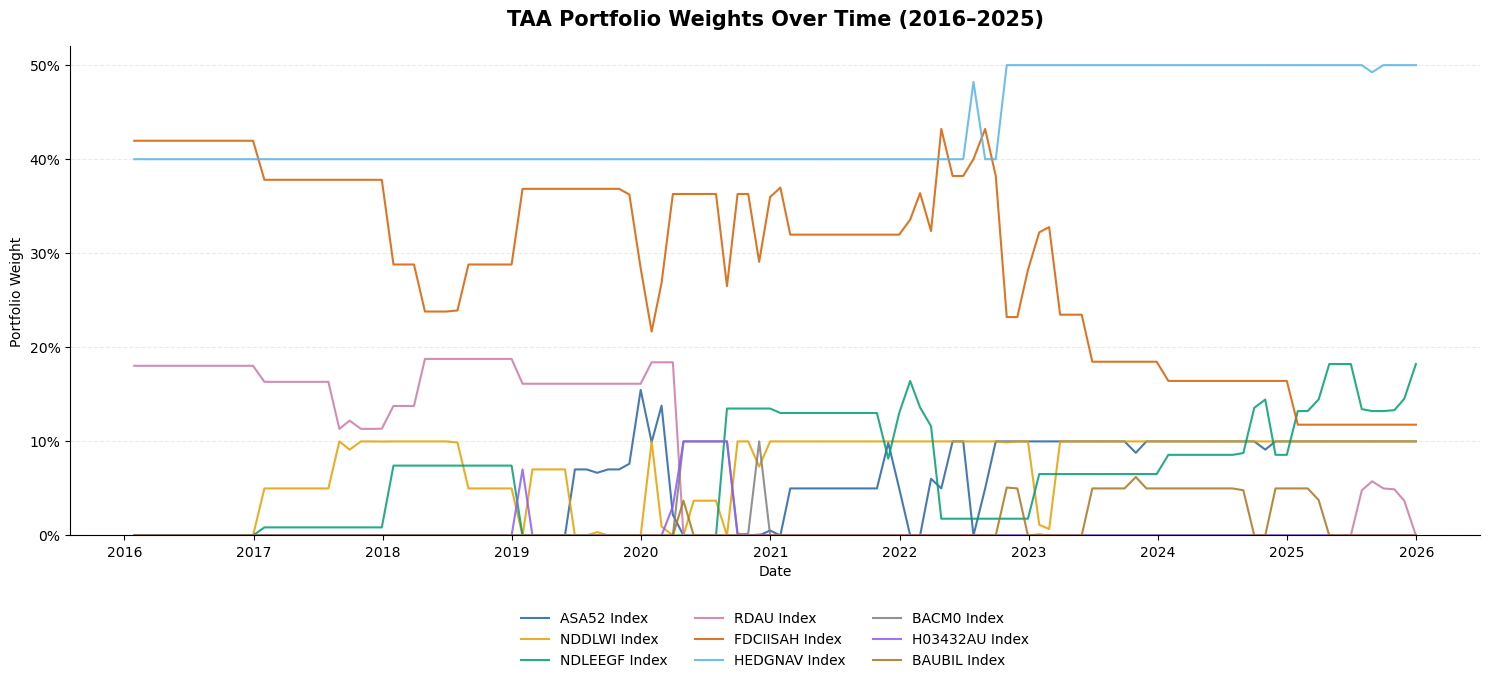

In [21]:

# ============================================================
# Q6 - Additional Figure: Combined TAA Portfolio Weights
# ============================================================

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import PercentFormatter

# Use the same monthly TAA weights as Step 11
dates = weight_history["Date"]

# Check that portfolio weights sum to 100%
assert np.allclose(
    weight_history[ASSETS].sum(axis=1),
    1.0,
    atol=1e-6
)

# Plot all nine asset weights in one figure
colors = [
    "#2563A6", "#E69F00", "#009E73",
    "#CC79A7", "#D55E00", "#56B4E9",
    "#7F7F7F", "#8B5CF6", "#A6761D"
]

fig, ax = plt.subplots(figsize=(15, 7))

for asset, color in zip(ASSETS, colors):
    ax.plot(
        dates,
        weight_history[asset],
        label=asset,
        color=color,
        linewidth=1.5,
        alpha=0.85
    )

ax.set_title(
    "TAA Portfolio Weights Over Time (2016–2025)",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Date")
ax.set_ylabel("Portfolio Weight")

ax.set_ylim(0, 0.52)
ax.set_yticks([0, 0.1, 0.2, 0.3, 0.4, 0.5])
ax.yaxis.set_major_formatter(PercentFormatter(1.0))

ax.xaxis.set_major_locator(mdates.YearLocator(1))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

ax.grid(axis="y", linestyle="--", alpha=0.25)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.13),
    ncol=3,
    frameon=False,
    fontsize=10
)

fig.tight_layout()

fig.savefig(
    "Q6_Additional_Weights_Line.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
